In [1]:
import sys,warnings
# sys.path.append('./DevEndo/') # change to the path where devendo.py stript located.
# import devendo as de
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import anndata, re,os
from scipy.sparse import csr_matrix,csc_matrix, find
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sc.settings.set_figure_params(dpi=100, facecolor='white')
pd.set_option("display.max_rows", 40)
pd.set_option("display.precision", 2)

In [ ]:
adata = sc.read_h5ad('../original_data/sted-ec.h5ad')


In [3]:
adata

AnnData object with n_obs × n_vars = 70915 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'

In [4]:
adata
adata.obs["day"].unique()

[7.00, 7.50, 7.75, 8.00, 8.50, ..., 17.0, 17.5, 18.0, 18.5, 19.0]
Length: 26
Categories (26, float64): [7.00, 7.50, 7.75, 8.00, ..., 17.5, 18.0, 18.5, 19.0]

/home/yaolab/mzhou10/.conda/envs/cdecoder/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/yaolab/mzhou10/.conda/envs/cdecoder/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/yaolab/mzhou10/.conda/envs/cdecoder/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


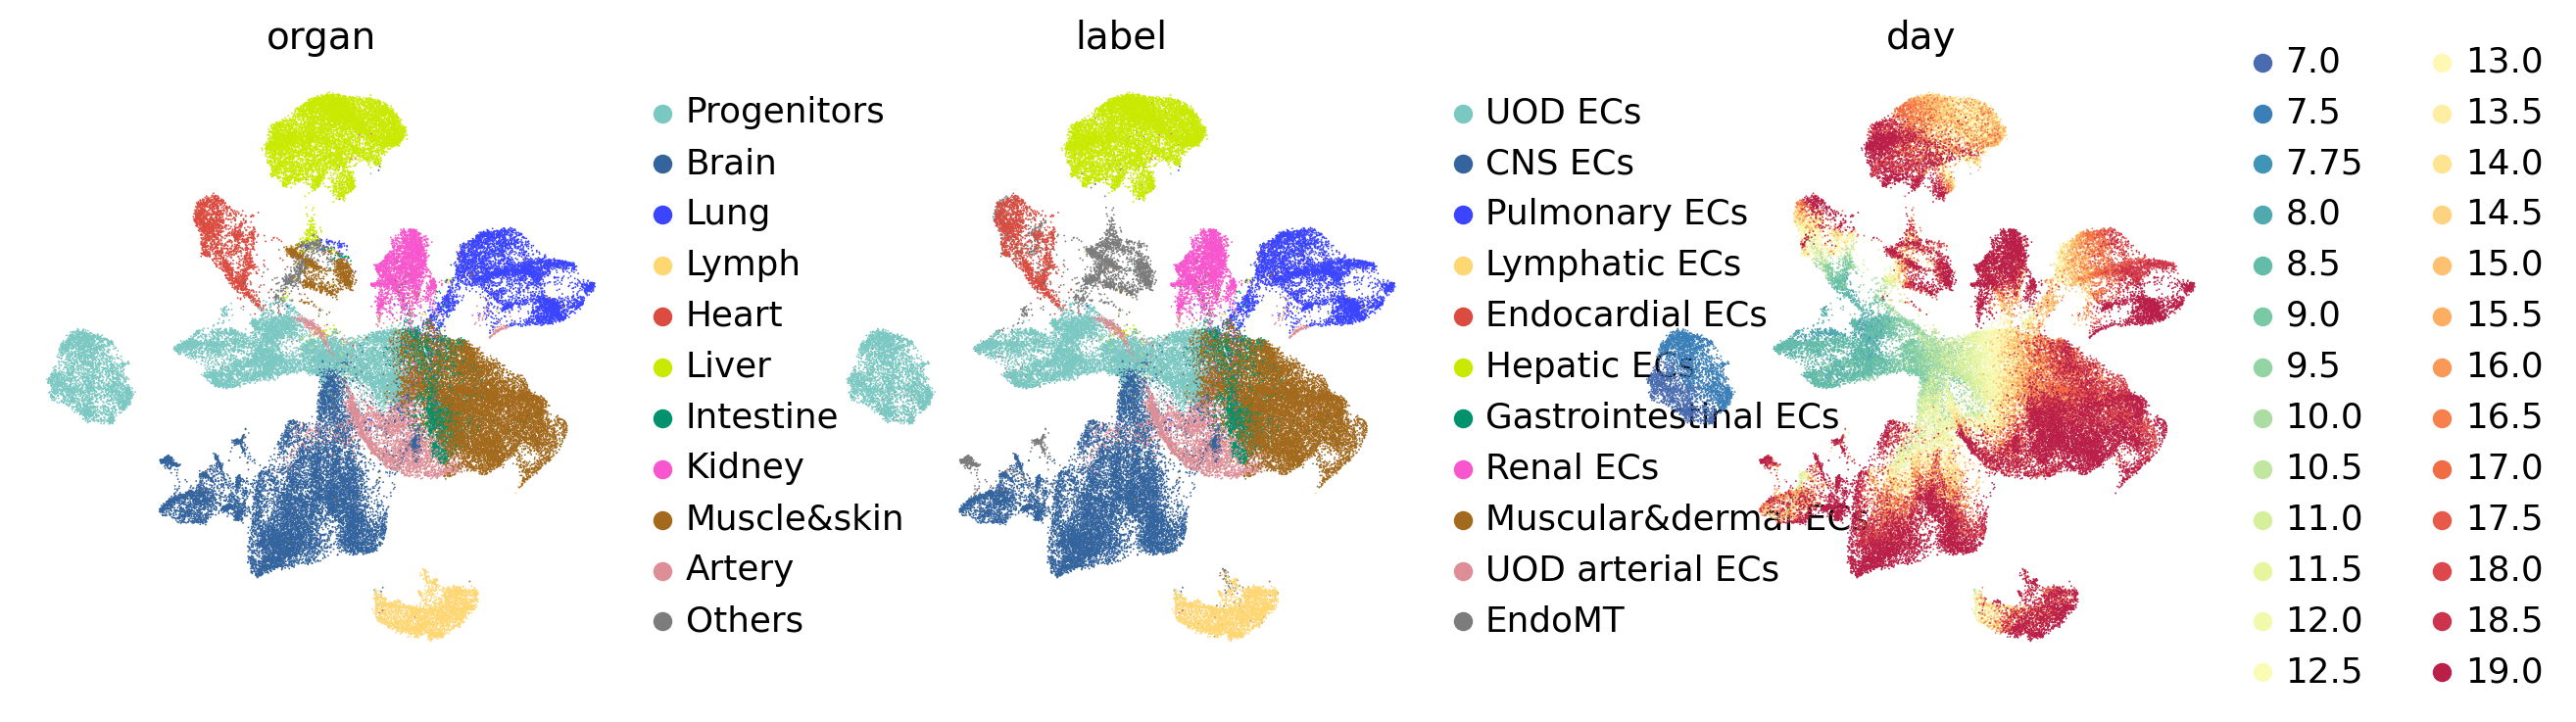

In [5]:
sc.pl.umap(adata, color = ['organ','label','day'], frameon=False)

In [6]:
# integer_days = list(range(7, 20))
# print(integer_days)

In [7]:
adata_int_day = adata[adata.obs["day"].isin([7,8,9,10,11,12,13,14,15,16,17,18,19])].copy()
print(adata_int_day)
# adata_pre = adata_int_day[adata_int_day.obs["organ"] == "Intestine"].copy()
adata_pre = adata_int_day.copy()
print(adata_pre.obs["organ"].unique())

AnnData object with n_obs × n_vars = 43322 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
['Progenitors', 'Heart', 'Artery', 'Others', 'Brain', ..., 'Muscle&skin', 'Lymph', 'Lung', 'Kidney', 'Intestine']
Length: 11
Categories (11, object): ['Progenitors', 'Brain', 'Lung', 'Lymph', ..., 'Kidney', 'Muscle&skin', 'Artery', 'Others']


In [8]:
# adata_int_day_19 = adata[adata.obs["day"].isin([19])].copy()
# print(adata_int_day_19.obs["day"])
# # adata_pre = adata_int_day[adata_int_day.obs["organ"] == "Intestine"].copy()
# adata_19 = adata_int_day_19.copy()
# adata_19.obs["Group"] = adata_19.obs["day"]

# adata_19.write_h5ad(
#     f"test_data_day_19.h5ad"
# )
# # print(adata_19.obs["organ"].unique())

In [9]:

print("Total cells:", adata_pre.shape[0])

# shuffle indices
total_indices = np.arange(adata_pre.shape[0])
np.random.shuffle(total_indices)

# 70% train, 30% test
train_size = int(0.7 * adata_pre.shape[0])

train_indices = total_indices[:train_size]
test_indices = total_indices[train_size:]

train_cluster = adata_pre[train_indices, :].copy()
test_cluster = adata_pre[test_indices, :].copy()

print("Train:", train_cluster.shape)
print("Test:", test_cluster.shape)
train_cluster.obs["Group"] = train_cluster.obs["day"]
test_cluster.obs["Group"] = test_cluster.obs["day"]

# save h5ad
train_cluster.write_h5ad(
    f"total_days_train_data_70_percent.h5ad"
)

test_cluster.write_h5ad(
    f"total_days_test_data_30_percent.h5ad"
)

Total cells: 43322
Train: (30325, 55450)
Test: (12997, 55450)


In [10]:
adata_train = sc.read_h5ad('total_days_train_data_70_percent.h5ad')
adata_day_train_except_day19 = adata_train[adata_train.obs["Group"].isin([7,8,9,10,11,12,13,14,15,16,17,18])].copy()
# print(adata_day_train_except_day19)
adata_day_7_10_train = adata_train[adata_train.obs["Group"].isin([7,10])].copy()
adata_day_7_13_train = adata_train[adata_train.obs["Group"].isin([7,13])].copy()
adata_day_7_18_train = adata_train[adata_train.obs["Group"].isin([7,18])].copy()
print(adata_day_7_18_train)
adata_day_train_except_day19.write_h5ad("train_data_day_except_19.h5ad")
adata_day_7_10_train.write_h5ad("train_data_day_7_and_10.h5ad")
adata_day_7_13_train.write_h5ad("train_data_day_7_and_13.h5ad")
adata_day_7_18_train.write_h5ad("train_data_day_7_and_18.h5ad")

AnnData object with n_obs × n_vars = 3984 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'


In [11]:
adata_test = sc.read_h5ad('total_days_test_data_30_percent.h5ad')
adata_day_7_test= adata_test[adata_test.obs["Group"].isin([7])].copy()
# adata_day_7_13_test = adata_test[adata_test.obs["Group"].isin([7,13])].copy()
# adata_day_7_18_test = adata_test[adata_test.obs["Group"].isin([7,18])].copy()
adata_day_19_test= adata_test[adata_test.obs["Group"].isin([19])].copy()

adata_day_7_test.write_h5ad("test_data_day_7.h5ad")
# adata_day_7_13_test.write_h5ad("test_data_day_7_and_13.h5ad")
# adata_day_7_18_test.write_h5ad("test_data_day_7_and_18.h5ad")
adata_day_19_test.write_h5ad("test_data_day_19.h5ad")